## Algorithm: Solving the 1D Wave (Advection) Equation with FFT

### The PDE

$$\frac{\partial u}{\partial t} = -c \frac{\partial u}{\partial x}$$

This is a **first-order** wave equation -- the solution is the initial shape translating to the right at speed $c$ without deformation: $u(x,t) = u_0(x - ct)$.

### Initial Condition

$u_0(x) = \text{sech}(x) = 1/\cosh(x)$ -- a smooth bell-shaped pulse centered at $x = 0$.

### Approach 1: Fourier Domain Integration

In Fourier space, $\partial/\partial x$ becomes multiplication by $i\kappa$, so:

$$\frac{d\hat{u}}{dt} = -c \cdot (i\kappa) \cdot \hat{u}$$

Each mode evolves independently as $\hat{u}_k(t) = \hat{u}_k(0)\, e^{-ic\kappa_k t}$ -- a **phase shift** (rotation), not decay. This is why the wave translates without changing shape.

### Approach 2: Spatial Domain Integration

Instead of evolving Fourier coefficients, `rhsWaveSpatial` computes $\partial u/\partial x$ at each time step:

1. FFT the current $u(x)$ $\to$ $\hat{u}$
2. Multiply by $i\kappa$ $\to$ spectral derivative
3. iFFT back $\to$ $\partial u/\partial x$ in physical space
4. Return $-c \cdot \partial u/\partial x$

This keeps the state in physical space, using FFT only to compute the derivative spectrally.

### Key Difference from the Heat Equation

| | Heat equation | Wave equation |
|---|---|---|
| PDE | $u_t = a^2 u_{xx}$ | $u_t = -c\, u_x$ |
| Fourier multiplier | $-a^2\kappa^2$ (real, negative) | $-ic\kappa$ (imaginary) |
| Mode behavior | **Exponential decay** $e^{-a^2\kappa^2 t}$ | **Phase rotation** $e^{-ic\kappa t}$ |
| Effect | Smoothing / diffusion | Translation without distortion |

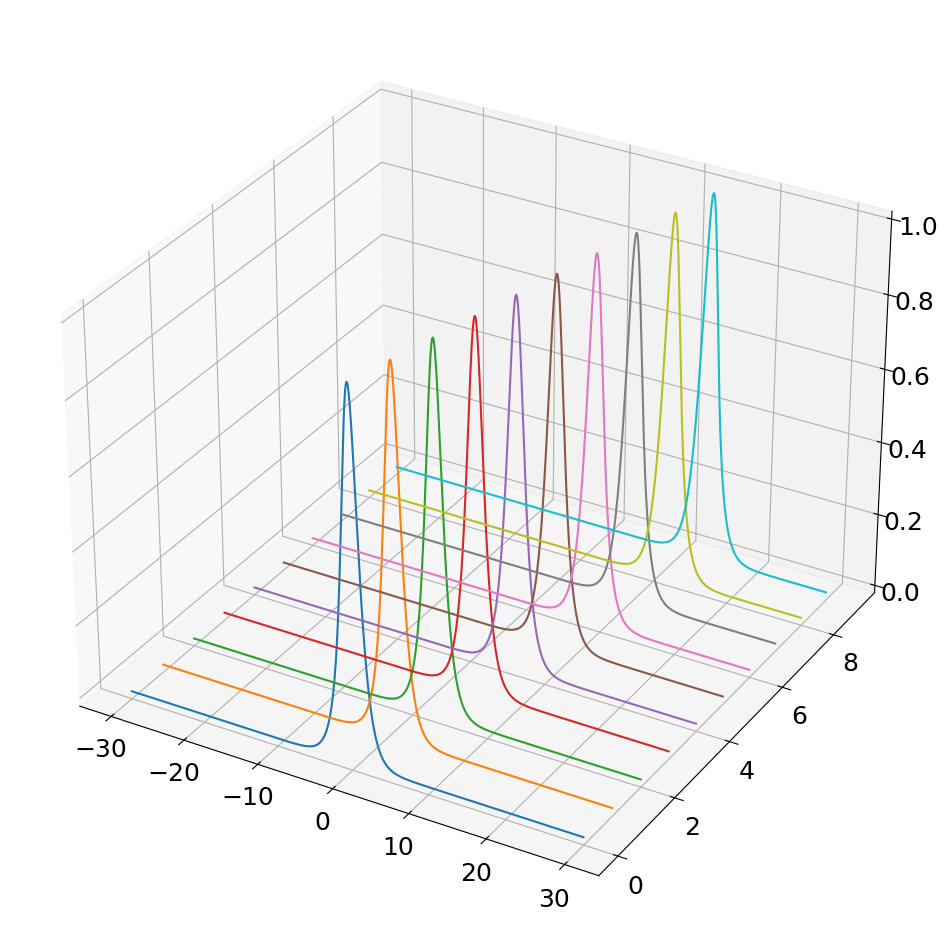

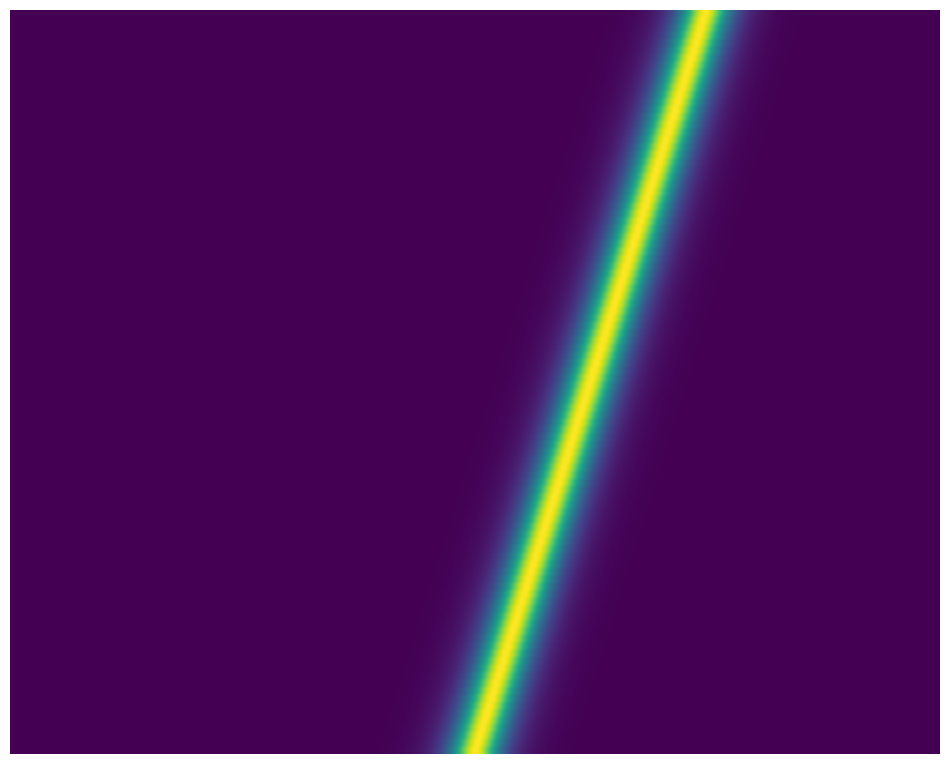

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
from mpl_toolkits.mplot3d import axes3d
plt.rcParams['figure.figsize'] = [12, 12]
plt.rcParams.update({'font.size': 18})

c = 6    # Wave speed
L = 60   # Length of domain
N = 1000 # Number of discretization points
dx = L/N
x = np.arange(-L/2,L/2,dx) # Define x domain

# Define discrete wavenumbers
kappa = 2*np.pi*np.fft.fftfreq(N, d=dx)

# Initial condition
u0 = 1/np.cosh(x)
u0hat = np.fft.fft(u0)

# SciPy's odeint function doesn't play well with complex numbers, so we recast 
# the state u0hat from an N-element complex vector to a 2N-element real vector
u0hat_ri = np.concatenate((u0hat.real,u0hat.imag))

# Simulate in Fourier frequency domain
dt = 0.025
t = np.arange(0,100*dt,dt)

def rhsWave(uhat_ri,t,kappa,c):
    uhat = uhat_ri[:N] + (1j) * uhat_ri[N:]
    d_uhat = -c*(1j)*kappa*uhat
    d_uhat_ri = np.concatenate((d_uhat.real,d_uhat.imag)).astype('float64')
    return d_uhat_ri

uhat_ri = odeint(rhsWave, u0hat_ri, t, args=(kappa,c))
uhat = uhat_ri[:,:N] + (1j) * uhat_ri[:,N:]

# Alternatively, simulate in spatial domain
def rhsWaveSpatial(u,t,kappa,c):
    uhat = np.fft.fft(u)
    d_uhat = (1j)*kappa*uhat
    d_u = np.fft.ifft(d_uhat).real
    du_dt = -c*d_u
    return du_dt

u_spatial = odeint(rhsWaveSpatial,u0,t,args=(kappa,c))

# Inverse FFT to bring back to spatial domain (Fourier approach)
u_fourier = np.zeros_like(uhat)

for k in range(len(t)):
    u_fourier[k,:] = np.fft.ifft(uhat[k,:])

u_fourier = u_fourier.real   

# Use the Fourier domain result for plotting (change to u_spatial to compare)
u = u_fourier


# Waterfall plot
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

u_plot = u[0:-1:10,:]
for j in range(u_plot.shape[0]):
    ys = j*np.ones(u_plot.shape[1])
    ax.plot(x,ys,u_plot[j,:])
    
# Image plot
plt.figure()
plt.imshow(np.flipud(u), aspect=8)
plt.axis('off')
plt.show()

 



## Note: Conjugate Symmetry and the Spectral Derivative

### Real functions have conjugate-symmetric DFT coefficients

For any real-valued function $u(x)$, the Fourier coefficients satisfy **Hermitian symmetry**:

$$\hat{u}_{-k} = \hat{u}_k^*$$

(In the array: $\hat{u}_{N-k} = \hat{u}_k^*$.) This guarantees that the imaginary parts cancel when summing sinusoids, producing a real signal.

### Multiplying by $i\kappa$ preserves this symmetry

The wavenumbers are **antisymmetric**: $\kappa_{-k} = -\kappa_k$. So for the negative-frequency term:

$$(i\kappa_{-k})\,\hat{u}_{-k} = i(-\kappa_k)\,\hat{u}_k^* = -i\kappa_k\,\hat{u}_k^*$$

And the conjugate of the positive-frequency term:

$$(i\kappa_k\,\hat{u}_k)^* = -i\kappa_k\,\hat{u}_k^*$$

These are equal, so conjugate symmetry is preserved:

$$(i\kappa_{-k})\,\hat{u}_{-k} = \left(i\kappa_k\,\hat{u}_k\right)^*$$

This means the iFFT of $i\kappa_k\hat{u}_k$ is **exactly real** -- the derivative of a real function is real.

### The conjugate pair picture

For a single frequency pair ($k$ and $-k$):

$$\hat{u}_k\,e^{i\kappa_k x} + \hat{u}_k^*\,e^{-i\kappa_k x} = 2\,\text{Re}\!\left(\hat{u}_k\,e^{i\kappa_k x}\right) \quad \text{(a real sinusoid)}$$

After multiplying by $i\kappa$:

$$i\kappa_k\hat{u}_k\,e^{i\kappa_k x} + (-i\kappa_k)\hat{u}_k^*\,e^{-i\kappa_k x} = 2\,\text{Re}\!\left(i\kappa_k\hat{u}_k\,e^{i\kappa_k x}\right) \quad \text{(still real)}$$

The multiplication by $i$ shifts the phase by $\pi/2$ -- sine becomes cosine -- which is exactly what a spatial derivative does.

### Why `.real` appears in the code

The `.real` in `np.fft.ifft(d_uhat).real` discards tiny floating-point imaginary noise ($\sim 10^{-16}$). Mathematically, the result is exactly real thanks to conjugate symmetry being preserved at every step.

## Note: Characteristics and Space-Time Equivalence

### The solution: $u(x, t) = u_0(x - ct)$

The value at position $x$ at time $t$ equals the initial value at position $x - ct$. Every point on the initial profile drifts to the right at speed $c$. A "parcel" starting at $x_0$ is found at $x_0 + ct$ at time $t$.

### Characteristic lines

The paths along which the solution is constant are called **characteristics**:

$$x - ct = \text{const} \quad \Rightarrow \quad \frac{dx}{dt} = c$$

If you "ride along" at speed $c$, you always see the same value. Moving 1 unit in time is the same as moving $c$ units in space.

### Space-time equivalence

A shift in time by $\Delta t$ is indistinguishable from a shift in space by $-c\Delta t$:

$$u(x, t + \Delta t) = u(x - c\Delta t,\; t)$$

The PDE $u_t = -cu_x$ literally says the rate of change in time equals $-c$ times the rate of change in space -- they are locked together at ratio $c$.

This is why the heatmap plot shows **diagonal stripes** -- the pattern moves at a constant slope $dx/dt = c$ through spacetime.